# ES for ht for classification 

## The NN

In [1]:
# Libs
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_classification as Models
import utils
import dataset as Dataset

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cpu


In [2]:
# Managing data 

number_of_samples = 20000
data_path = './data/WRT1V.parquet'

df = pd.read_parquet(data_path)
df = df.head(number_of_samples)
df.drop(columns=['Day'], inplace=True)

target_cols = ['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100']
# Set target cols to dtype int
df[target_cols] = df[target_cols].astype(int)

df.head()


,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Label_10,Label_20,Label_30,Label_50,Label_100
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1,1,1,1,1
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,2,2,1,1,1
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,0,0,1,1


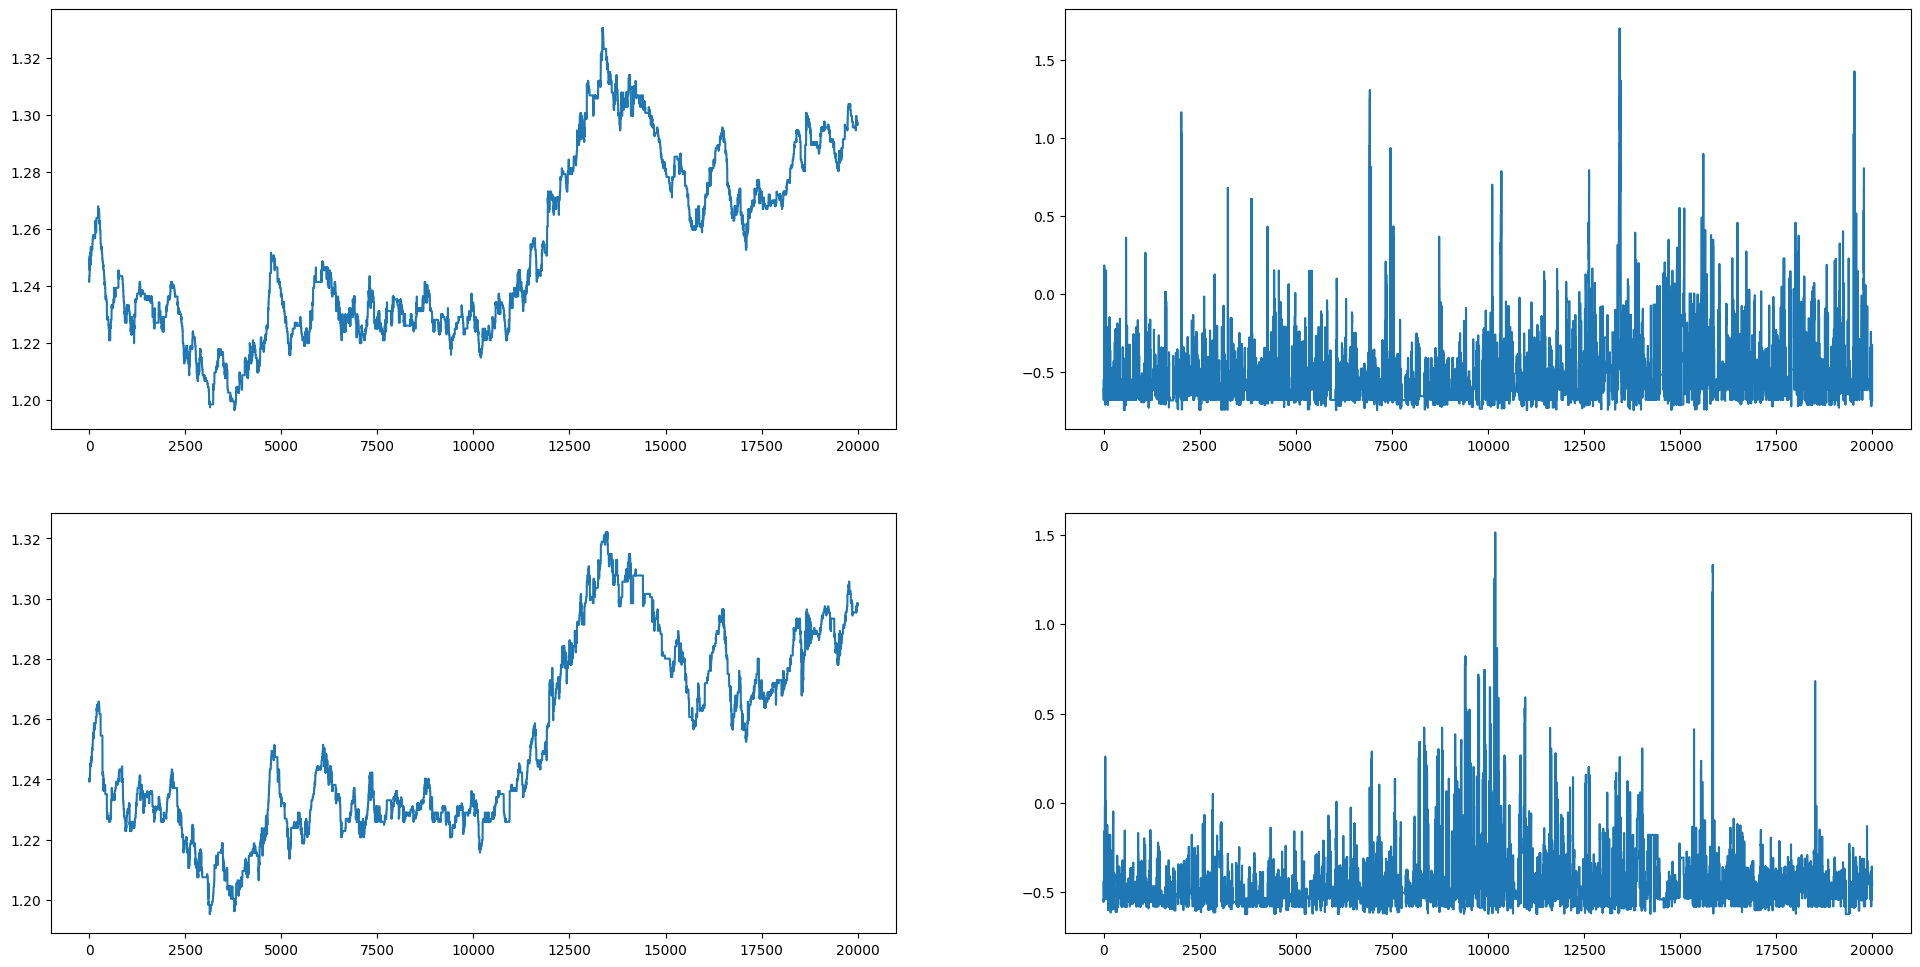

In [3]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()

In [4]:
logreturn = lambda x: np.log(x) - np.log(x.shift(1))

price_cols = [col for col in df.columns if 'P_' in col]
df[price_cols] = df[price_cols].apply(logreturn, axis=0)
df.dropna(inplace=True)

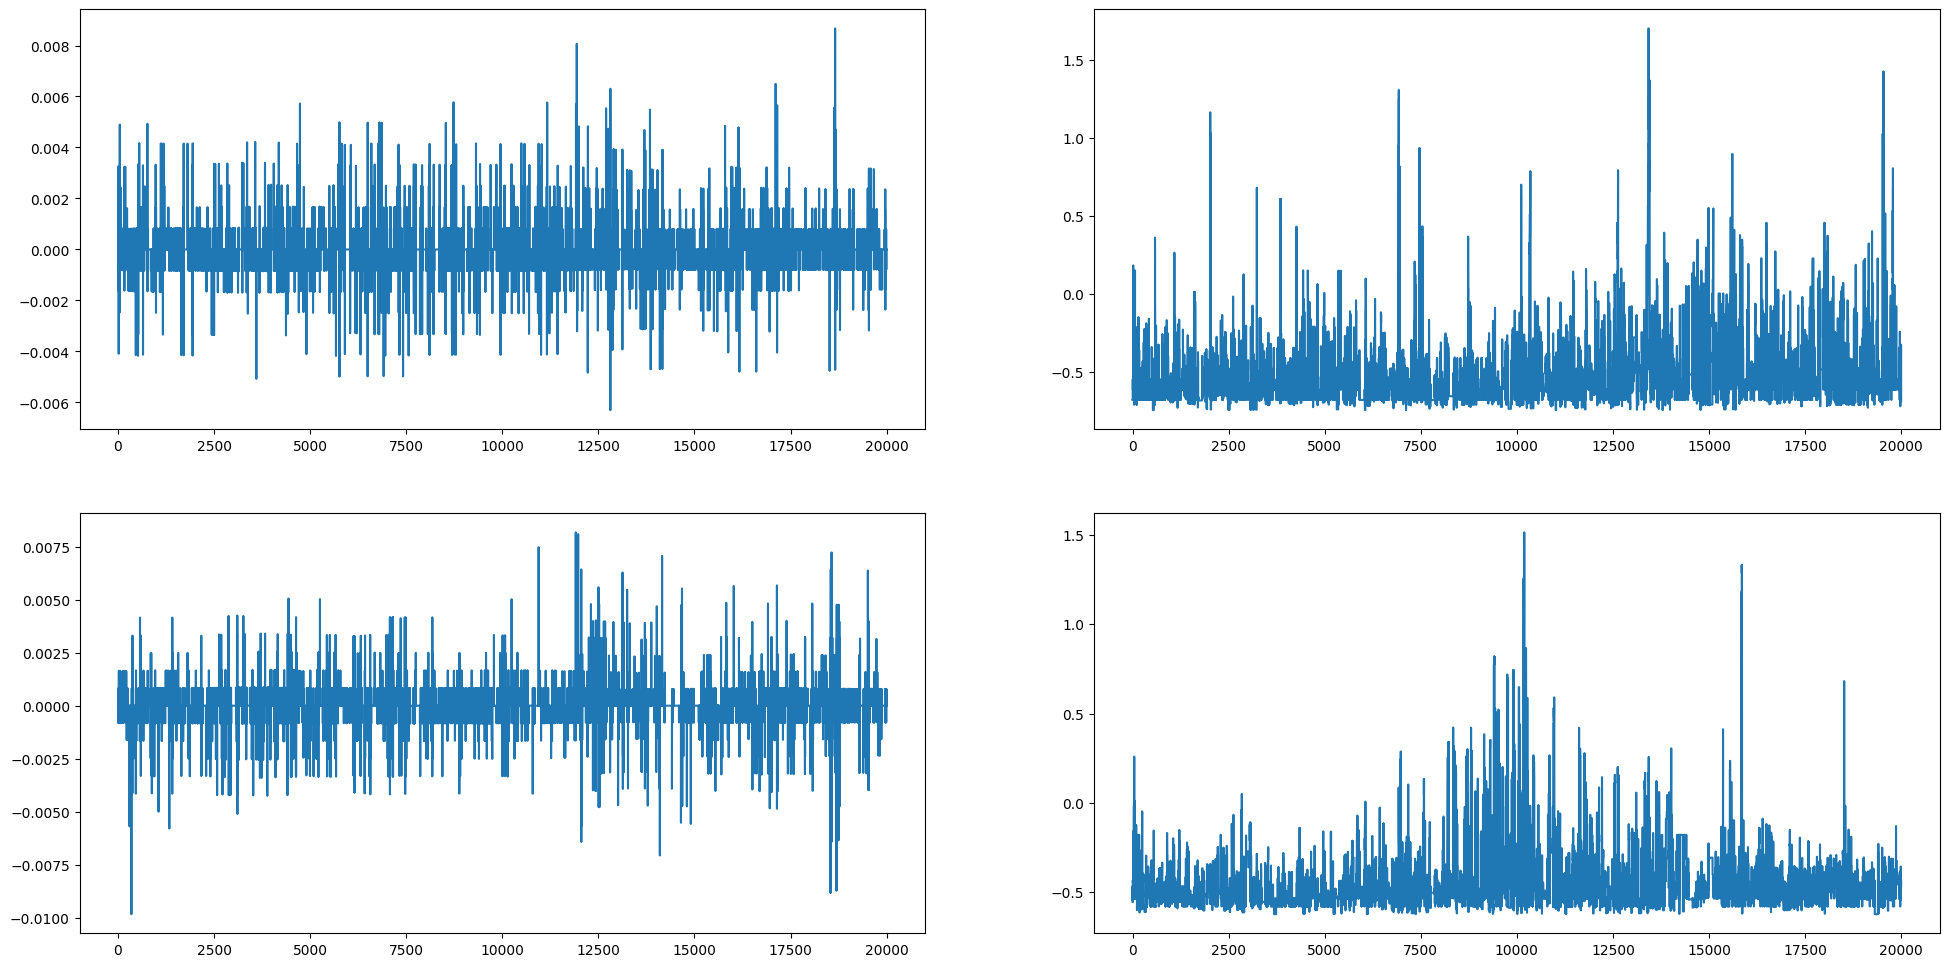

In [5]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()

In [6]:
# Split the dataframe into train and test
df_train, df_val, df_test = utils.DataTools.train_val_test_split(df)

# Split covariates and response variable(s)
X_train, y_train = utils.DataTools.split_x_y(df_train, target_cols)
X_val, y_val     = utils.DataTools.split_x_y(df_val, target_cols)
X_test, y_test   = utils.DataTools.split_x_y(df_test, target_cols)

# Standardize the covariates
scaler_X = preprocessing.StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

# Build tensors 
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, device=device, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, device=device, dtype=torch.long )

# Build TimeSeriesDataset
SEQ_LEN_X = 50
SEQ_LEN_Y = 1
OFFSET = 0
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)

# Build TimeSeriesLoader
BATCH_SIZE = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [7]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 13949 samples
Test dataset: 2951 samples


## The Sam Evolutionary Strategy Tuning 

In [8]:
# Import tuning module
import es_tuning_LSTM_functions 

In [10]:
# Example usage
max_fitness_evaluations = 100        # change it to 100
num_epochs_per_nn_evaluation = 15    # change it to 15

mu_population_size = 10              # change it to 10
lambda_offsprings_size = 15          # change it to 20

init_unitsNumber_interval = [32,128]

nn_training_data = dataloader_train
nn_validation_data = dataloader_val
nn_input_size = X_train.shape[1]
nn_output_size = 3*y_train.shape[1]

# device = cuda if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") 

csv_file_path = './csv_results/es_LSTM.csv'

init_layersNumber_interval = [1,1]  
init_activation_functions = [nn.ReLU] 
init_lr_interval = (5e-6, 5e-3)
init_dropout_interval = (0.0, 0.4)
maximize_fitness = False

tornamentPercentage_for_offspringGeneration = 0.2
p_crossover_vs_mutation = 0.75
structure_k_value_for_crossover = 0
structure_lb_size = 32
structure_ub_size = 150
lr_k = 0
dropout_k = 0
lr_lb = 5e-6
lr_ub = 5e-3
dropout_lb = 0.0
dropout_ub = 0.4


best_individual_ever = es_tuning_LSTM_functions.es_lambdaMu_sld_classification(
    max_fitness_evaluations = max_fitness_evaluations,
    mu_population_size = mu_population_size,
    init_layersNumber_interval = init_layersNumber_interval,
    init_unitsNumber_interval = init_unitsNumber_interval,
    init_activation_functions = init_activation_functions,
    init_lr_interval = init_lr_interval,
    init_dropout_interval = init_dropout_interval,
    nn_training_data = nn_training_data,
    nn_validation_data = nn_validation_data,
    num_epochs_per_nn_evaluation = num_epochs_per_nn_evaluation,
    nn_input_size = nn_input_size,
    nn_output_size = nn_output_size,
    device = device,
    maximize_fitness = maximize_fitness,
    lambda_offsprings_size = lambda_offsprings_size,
    tornamentPercentage_for_offspringGeneration = tornamentPercentage_for_offspringGeneration,
    p_crossover_vs_mutation = p_crossover_vs_mutation,
    structure_k_value_for_crossover = structure_k_value_for_crossover,
    structure_lb_size = structure_lb_size,
    structure_ub_size = structure_ub_size,
    lr_k = lr_k,
    dropout_k = dropout_k,
    lr_lb = lr_lb,
    lr_ub = lr_ub,
    dropout_lb = dropout_lb,
    dropout_ub = dropout_ub,
    csv_file_path=csv_file_path)

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Training:   0%|          | 0/1 [00:00<?, ?it/s]

Estimated time: 0 hours and 0 minutes
Generation 1: 10 fitness evaluations, best individual: Individual: nn_gene = [60], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.0013995988971458701, dropout = 0.15299456579140772 | nn_sol = [60], Fitness = 5.142392145690097
Best individual ever: Individual: nn_gene = [60], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.0013995988971458701, dropout = 0.15299456579140772 | nn_sol = [60], Fitness = 5.142392145690097


## Test the tuned model 

In [18]:
import sam_plots

In [14]:
# Create model with standard parameters
params = {
    'input_size': X_train.shape[1],
    'output_size': 3*y_train.shape[1],
    'hidden_size': 64,
    'num_layers': 2,
    'dropout_rate': 0.15
}
model = Models.LSTM(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-4
n_epochs = 10
criterion = utils.loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
std_training_info = utils.ModelTools.train(
    model_id = 'Basic LSTM',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

In [15]:
# Create model with tuned parameters
params = {
    'input_size': X_train.shape[1],
    'output_size': 3*y_train.shape[1],
    'hidden_size': best_individual_ever.structure_solution[0],
    'num_layers': 2,
    'dropout_rate': best_individual_ever.dropout_solution
}
model = Models.LSTM(**params).to(device)

# Define loss function and optimizer
learning_rate = best_individual_ever.lr_solution
n_epochs = 10
criterion = utils.loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
tuned_training_info = utils.ModelTools.train(
    model_id = 'Basic LSTM',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

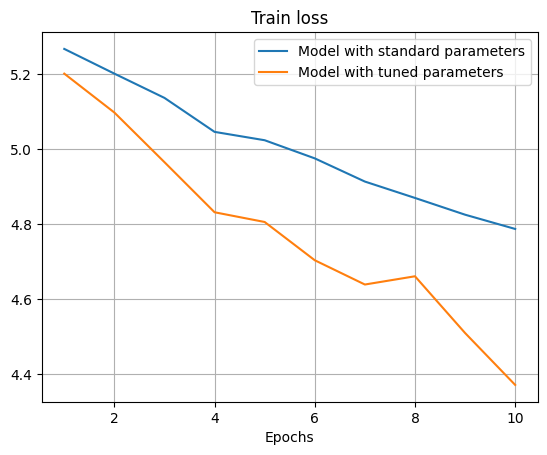

In [19]:
sam_plots.plot_2_histories(
    std_training_info['train_loss'],
    tuned_training_info['train_loss'],
    "Train loss",
    "Model with standard parameters",
    "Model with tuned parameters"
    )

##